# COMPASS — Comparative Modeling of Parameter-Space Synergy and Sampling

**Are higher-order parameter interactions in phenotype-constrained neuronal models
neuron-specific biological signatures, or generic consequences of nonlinear model
structure, parameter sampling, and conditioning on selected outputs?**

This notebook regenerates every figure and number in `docs/RESULTS.md` from the
frozen derived tables in `results/analyses/`. It contains **no analysis logic**:
all estimators, ensembles and statistics live in `src/compass/` and are executed
by the `tools/run_*.py` scripts. Re-running this notebook from a clean kernel
reproduces the report exactly.

Pipeline that produced the inputs:

```bash
python tools/fetch_models.py          # download panel, record provenance + hashes
python tools/build_mechanisms.py      # compile per-model NEURON mechanism libraries
python tools/numerical_qc.py --spatial  # first-pass QC (historical record only)
python tools/convergence_audit.py <m>   # feature-level convergence -> production dt
python tools/canonical_audit.py       # manifests, built under CAMPAIGN_SOLVER
python tools/run_campaign.py --experiment screening
python tools/run_analysis.py --experiment screening
python tools/run_benchmarks.py
python tools/run_sobol.py
python tools/run_perturbations.py
python tools/run_crossmodel.py
```

**Reporting discipline (blueprint §30).** Four kinds of statement are kept apart
throughout:

| level | meaning | established here? |
|---|---|---|
| **Observed** | a metric has a value in a declared ensemble | yes |
| **Statistical** | the ensemble is synergy- or redundancy-dominated under a stated estimator | yes |
| **Functional** | joint perturbations are non-additive in the model equations | **partly — see below** |
| **Biological** | the same interaction occurs in real neurons | **no — out of scope** |

The functional level is qualified because the perturbation battery gives a
2–3× enrichment whose paired tests are not significant (p = 0.195, 0.078), whose
size depends on which readout is measured, and which falls below the readout's
imprecise per tuple once background variability is accounted for. Non-additivity is *observed*;
that it identifies the tuples statistical synergy selects is **not established**.

In [23]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

from compass.reporting import figures as FG
FG.apply_style()

AN  = ROOT / "results" / "analyses"
MAN = ROOT / "results" / "manifests"
TR  = ROOT / "results" / "traces"
PROV = ROOT / "data" / "provenance"
EXP = "screening"

def load(name, kind="parquet"):
    p = AN / name
    if not p.exists():
        print(f"  (missing {name})"); return None
    return pd.read_parquet(p) if kind == "parquet" else json.loads(p.read_text())

endpoints  = load(f"endpoints_annotated_{EXP}.parquet")
if endpoints is None:
    endpoints = load(f"endpoints_{EXP}.parquet")
curves     = load(f"order_curves_{EXP}.parquet")
tuple_sc   = load(f"tuple_scores_{EXP}.parquet")
rsi_tab    = load(f"rsi_{EXP}.parquet")
cond_shift = load("conditioning_shift.parquet")
cov_shift  = load("covariance_shift.parquet")
vpart      = load("variance_partition.parquet")
lomo       = load("lomo.parquet")
clf        = load("classification.parquet")
stability  = load("module_stability.parquet")
sobol_sum  = load("sobol_summary.parquet")
sobol_idx  = load("sobol_indices.parquet")
sobol_conv = load("sobol_convergence.parquet")
pert       = load("perturbations.parquet")
resolution = load("perturbation_inference.parquet")
bench      = load("benchmarks.json", "json")
decision   = load("decision.json", "json")
mixed      = load("mixed_effects.json", "json")

print(f"endpoints rows      : {0 if endpoints is None else len(endpoints)}")
print(f"order-curve rows    : {0 if curves is None else len(curves)}")
print(f"per-tuple scores    : {0 if tuple_sc is None else len(tuple_sc)}")

endpoints rows      : 410
order-curve rows    : 1230
per-tuple scores    : 46876


---
## 1. Provenance and the model panel

Every model was obtained from a citable archive and hashed. The panel spans the
blueprint §6.1 slots and contains **two independently developed cortical
pyramidal models** — one from the Blue Brain Project lineage and one that was
never touched by the BBP pipeline — which is what separates neuronal identity
from laboratory implementation (§6.4).

In [24]:
dl = json.loads((PROV / "downloads.json").read_text())
prov = pd.DataFrame([{
    "source": d["source"], "id": d["id"], "slot": d["slot"],
    "status": d["status"], "sha256/commit": (d.get("sha256") or d.get("commit",""))[:16],
    "n_mod": d.get("n_mod"),
} for d in dl])
display(prov)

rows = []
for p in sorted(MAN.glob("canonical_*.json")):
    r = json.loads(p.read_text()); m = r["manifest"]
    rows.append({
        "model_id": r["model_id"], "class": m["neuron_class"], "lab": m["lab"],
        "pipeline": m["pipeline"], "compartments": r["n_compartments"],
        "params": r["n_parameters"], "temp_C": m["temperature_c"],
        "V_rest_mV": round(r["resting_potential_mV"], 1),
        "rheobase_nA": None if r["rheobase_nA"] is None else round(r["rheobase_nA"], 4),
        "spont_Hz": round(r["spontaneous_rate_Hz"], 1),
        "s/protocol": r["mean_protocol_s"],
    })
panel = pd.DataFrame(rows).set_index("model_id").loc[
    [m for m in FG.MODEL_ORDER if m in {r["model_id"] for r in rows}]]
display(panel)

,source,id,slot,status,sha256/commit,n_mod
0,modeldb,123623,cortical_rs_and_fs,ok,8a5866f60fdec445,5
1,modeldb,97747,fast_spiking_interneuron,ok,20aac9874d0a88df,0
2,modeldb,48332,cerebellar_purkinje,ok,2b6a9fd3902eb62f,9
3,modeldb,2488,cortical_pyramidal_a,ok,ab40702bb35495ca,6
4,modeldb,139653,cortical_pyramidal_b,ok,dc3ae128776cc861,26
5,modeldb,2796,hippocampal_ca1,ok,f56fefb2d3a8aa3f,5
6,modeldb,267306,dopaminergic,ok,4e69988ff6530502,9
7,modeldb,2017402,dopaminergic_alt,ok,45fafd6dcca8e87a,17
8,modeldb,267621,invertebrate_stg,ok,32cb4e476627b8c5,64
9,modeldb,17664,cerebellar_purkinje_alt,ok,72eb6af62bf99772,20


,class,lab,pipeline,compartments,params,temp_C,V_rest_mV,rheobase_nA,spont_Hz,s/protocol
model_id,,,,,,,,,,
hh_point,minimal_hh,hodgkin_huxley,independent,1,6,6.3,-65.0,0.0645,0.0,0.068
hh_cable,minimal_hh,hodgkin_huxley,independent,11,8,6.3,-63.8,0.1016,0.0,0.067
pospischil_rs,cortical_pyramidal_rs,destexhe,independent,1,8,36.0,-70.5,0.5449,0.0,0.059
pospischil_fs,cortical_interneuron_fs,destexhe,independent,1,7,36.0,-70.0,0.3867,0.0,0.063
khaliq_purkinje,cerebellar_purkinje,raman,independent,1,10,22.0,-68.2,0.0000,28.6,0.201
mainen_l5pc,cortical_pyramidal,mainen_sejnowski,independent,2304,10,37.0,-70.4,0.1641,0.0,17.160
migliore_ca1,hippocampal_pyramidal,migliore,independent,1106,8,34.0,-65.0,0.1777,0.0,5.006
bbp_l5pc,cortical_pyramidal,blue_brain_project,bbp,642,15,34.0,-77.1,0.3369,0.0,2.329


### Numerical quality control

The campaign runs **deterministic fixed steps**, not CVODE: under a broad prior
CVODE's cost depends on how stiff each individual sample happens to be
(profiling `mainen_l5pc` gave a median of 11 s per sample but individual samples
of 233 s and 307 s), which cannot be budgeted and risks biasing the ensemble if
any sample were abandoned.

**Two audits, and only one of them chooses the settings.** `numerical_qc.json`
below is the *first-pass* sweep, which compared spike count at the single
canonical parameter point. It is retained as a historical record and is shown
here for that reason only. Production settings come from
`tools/convergence_audit.py`, which compares **all 13 conditioning features on
six samples drawn from each model's own prior** against a refined reference;
four of eight models failed that stricter check and were re-simulated. Compare
the `audit_choice` column (first pass) with `campaign_dt_ms` (what actually
ran) — where they differ, the campaign follows the stricter audit.

Until the 2026-08-06 audit these two sources disagreed silently: the canonical
manifests were built from the first-pass settings (CVODE at 0.025 ms) while the
ensembles ran fixed-step. `CAMPAIGN_SOLVER` is now the single authority, and
`tests/unit/test_solver_contract.py` fails if a stored manifest drifts from it.

`mainen_l5pc` remains **not spatially converged** even at its production mesh:
against a reference refined in both time and space it fails one conditioning
feature (`adaptation_index`) on one of seven samples, through a single
threshold-adjacent spike.

In [25]:
qc = json.loads((PROV / "numerical_qc.json").read_text())
rows = []
for r in qc:
    accepted = [k for k, v in r["accepted"].items() if v]
    sp = r.get("spatial", {})
    rows.append({
        "model_id": r["model_id"],
        "accepted_timesteps": ", ".join(accepted),
        "audit_choice": r["chosen"],
        "spatial_converged_as_published":
            None if not sp.get("applicable") else
            sp["levels"]["as_published"]["matches_finest"],
        "spatial_choice": sp.get("chosen", "-"),
    })
qcdf = pd.DataFrame(rows).set_index("model_id")
from compass.workflows.simulate import CAMPAIGN_SOLVER
qcdf["campaign_dt_ms"] = [CAMPAIGN_SOLVER.get(m, {}).get("dt_ms") for m in qcdf.index]
display(qcdf)

,accepted_timesteps,audit_choice,spatial_converged_as_published,spatial_choice,campaign_dt_ms
model_id,,,,,
bbp_l5pc,"fixed_0.0125, fixed_0.025, fixed_0.05, cvode",cvode,True,as_published,0.02500
hh_point,"fixed_0.0125, fixed_0.025, fixed_0.05, cvode",cvode,None,-,0.02500
hh_cable,"fixed_0.0125, fixed_0.025, fixed_0.05, cvode",cvode,True,as_published,0.05000
pospischil_rs,"fixed_0.0125, fixed_0.025, fixed_0.05, cvode",fixed_0.05,None,-,0.05000
pospischil_fs,"fixed_0.0125, fixed_0.025, cvode",fixed_0.025,None,-,0.02500
khaliq_purkinje,"fixed_0.0125, cvode",cvode,None,-,0.00625
mainen_l5pc,"fixed_0.0125, fixed_0.025, cvode",cvode,True,as_published,0.01250
migliore_ca1,"fixed_0.0125, cvode",cvode,False,d_lambda_2x,0.02500


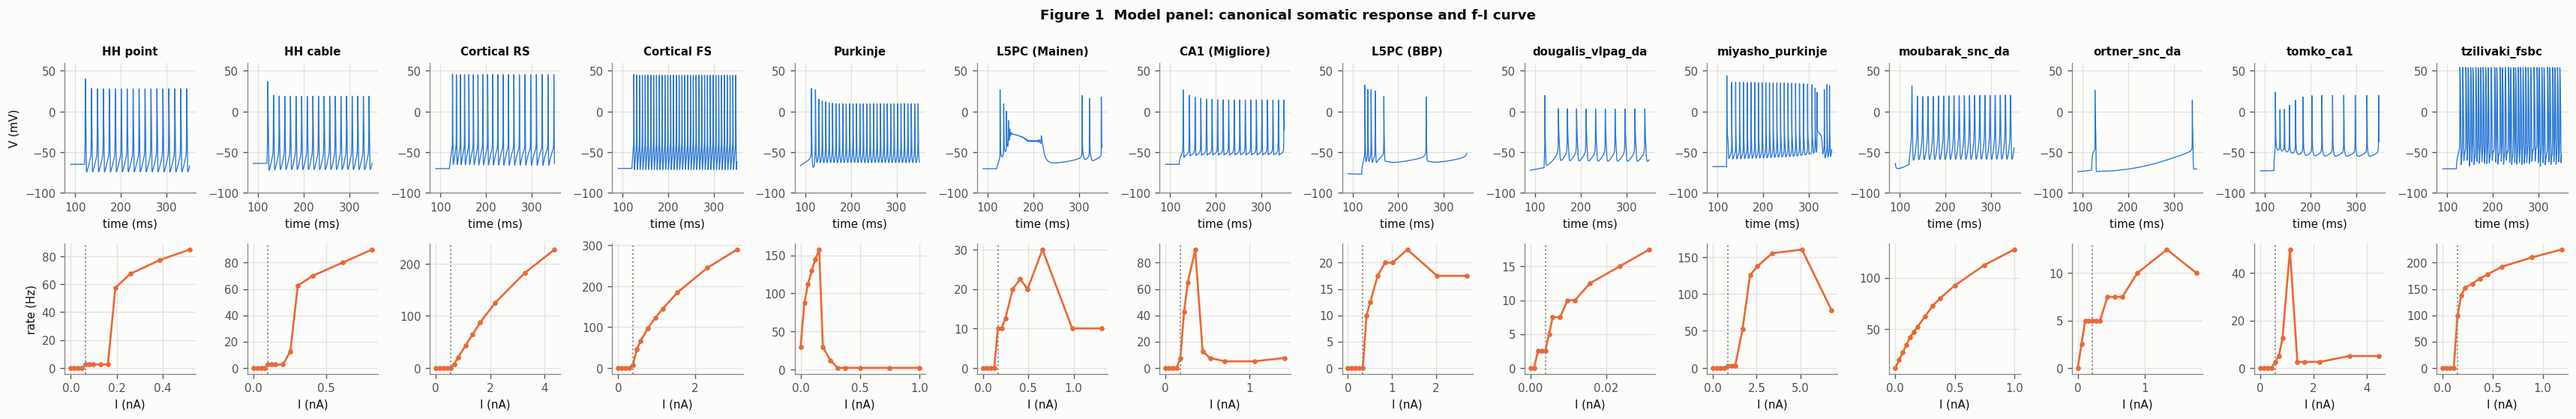

In [26]:
fig = FG.fig_model_panel(MAN, TR); plt.show()

---
## 2. Estimator validation (blueprint WP5)

No neuronal number is believed until the estimators are shown to recover known
structure and the sign conventions are verified against analytic systems.

Conventions, frozen and asserted in `tests/numerical/`:

* **O-information** $\Omega>0$ → redundancy, $\Omega<0$ → synergy.
* **RSI** $= I(X_{1..n};Y)-\sum_i I(X_i;Y)$: $>0$ → synergy, $<0$ → redundancy.

Note the opposite polarity of the two — the most common sign error in this
literature.

,case,expected,rsi,joint,sum_individual,correct
0,sum_of_independent_inputs,synergy,1.9735,2.6622,0.6887,True
1,duplicated_predictors,redundancy,-1.8243,2.1133,3.9376,True
2,single_informative_predictor,none,0.0000,0.8033,0.8033,True


all RSI sign conventions correct: True


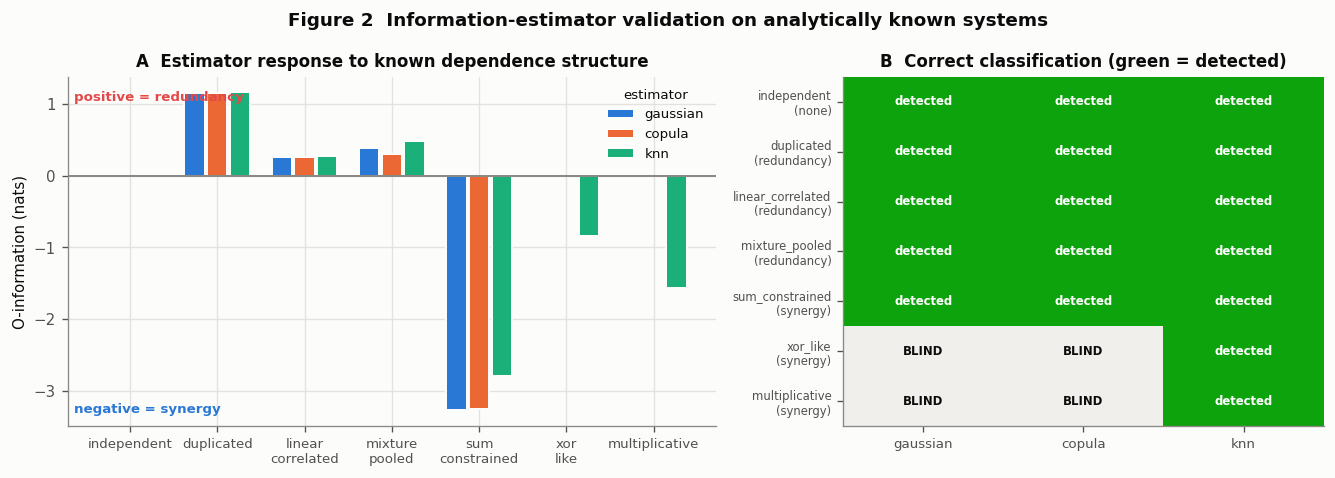

In [27]:
sign = pd.DataFrame(bench["rsi_sign_validation"])
display(sign[["case","expected","rsi","joint","sum_individual","correct"]].round(4))
print("all RSI sign conventions correct:", bool(sign["correct"].all()))
fig = FG.fig_estimator_validation(bench); plt.show()

**Finding E1 — the Gaussian and copula estimators are structurally blind to
product-type synergy.** Both return $\Omega \approx 0.000$ for `xor_like`
($x_3=x_1x_2$) and `multiplicative` ($x_4=x_1x_2x_3$), where the k-NN estimator
returns $-0.84$ and $-1.57$ nats. Both *do* detect sum-type synergy
(`sum_constrained`, $\Omega=-3.27$), and all three agree on every redundancy
case. So the covariance-based estimator used throughout the published literature
can only see synergy that is already expressed in second-order statistics. This
is a limitation of the instrument, not of the systems, and it bounds what any
Gaussian O-information result — including the ones below — can claim.

---
## 3. Does conditioning manufacture higher-order structure?

The first secondary question of the blueprint (§2.2.1): *does phenotype
conditioning create higher-order dependence when the original prior is
independent?*

Every ensemble here starts from the **same** independent quasi-random prior. The
only thing that changes across the tolerance series is how tightly the accepted
samples are required to reproduce the canonical model's own phenotype.

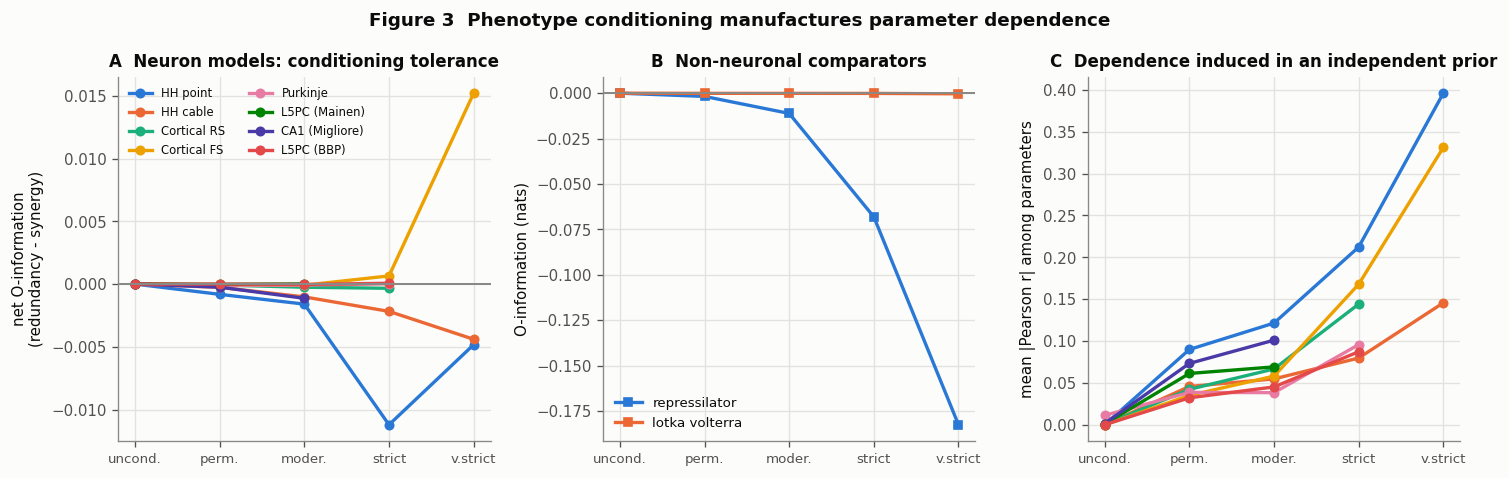

In [28]:
fig = FG.fig_conditioning_effect(endpoints, bench); plt.show()

In [29]:
cs = cond_shift[(cond_shift.estimator=="gaussian") &
                (cond_shift.protocol_family=="absolute") &
                (cond_shift.metric=="max_z")]
tbl = (cs.pivot_table(index="model_id", columns="tolerance",
                      values=["d_net_o_information","d_mean_abs_pearson","acceptance_rate"])
         .reindex([m for m in FG.MODEL_ORDER if m in set(cs.model_id)]))
display(tbl.round(4))
g = cs.groupby("model_id")["d_net_o_information"].mean()
print(f"models shifting toward synergy after conditioning: {(g<0).sum()}/{len(g)}")
print(f"models gaining parameter correlation           : "
      f"{(cs.groupby('model_id')['d_mean_abs_pearson'].mean()>0).sum()}/{len(g)}")

acceptance_rate                                 \
tolerance              moderate permissive  strict very_strict   
model_id                                                         
hh_point                 0.2456     0.3226  0.1016      0.0187   
hh_cable                 0.2402     0.3379  0.1517      0.0355   
pospischil_rs            0.4629     0.6423  0.0823         NaN   
pospischil_fs            0.6423     0.8108  0.1080      0.0081   
khaliq_purkinje          0.5616     0.6709  0.1136         NaN   
migliore_ca1             0.4336     0.5469     NaN         NaN   
bbp_l5pc                 0.2256     0.3135  0.0732         NaN   

                d_mean_abs_pearson                                 \
tolerance                 moderate permissive  strict very_strict   
model_id                                                            
hh_point                    0.1214     0.0899  0.2123      0.3961   
hh_cable                    0.0548     0.0457  0.0797      0.1457   
pospischil_rs               0.0665     0.0422  0.1440         NaN   
pospischil_fs               0.0581     0.0350  0.1678      0.3312   
khaliq_purkinje             0.0271     0.0273  0.0844         NaN   
migliore_ca1                0.0996     0.0718     NaN         NaN   
bbp_l5pc                    0.0481     0.0367  0.0933         NaN   

                d_net_o_information                                 
tolerance                  moderate permissive  strict very_strict  
model_id                                                            
hh_point                    -0.0016    -0.0008 -0.0112     -0.0048  
hh_cable                    -0.0010    -0.0003 -0.0022     -0.0044  
pospischil_rs               -0.0003    -0.0001 -0.0003         NaN  
pospischil_fs               -0.0001    -0.0001  0.0007      0.0152  
khaliq_purkinje             -0.0001    -0.0001  0.0000         NaN  
migliore_ca1                -0.0011    -0.0003     NaN         NaN  
bbp_l5pc                    -0.0000    -0.0000  0.0001         NaN

models shifting toward synergy after conditioning: 5/7
models gaining parameter correlation           : 7/7


---
## 4. O-information order curves with matched-search surrogate controls

Extreme O-information values grow simply because the number of tuples grows with
order. Every order is therefore accompanied by a family-wise surrogate band built
from column-shuffled ensembles evaluated over the **same number of tuples**
(blueprint §16.2). Only excursions outside that band are interpretable.

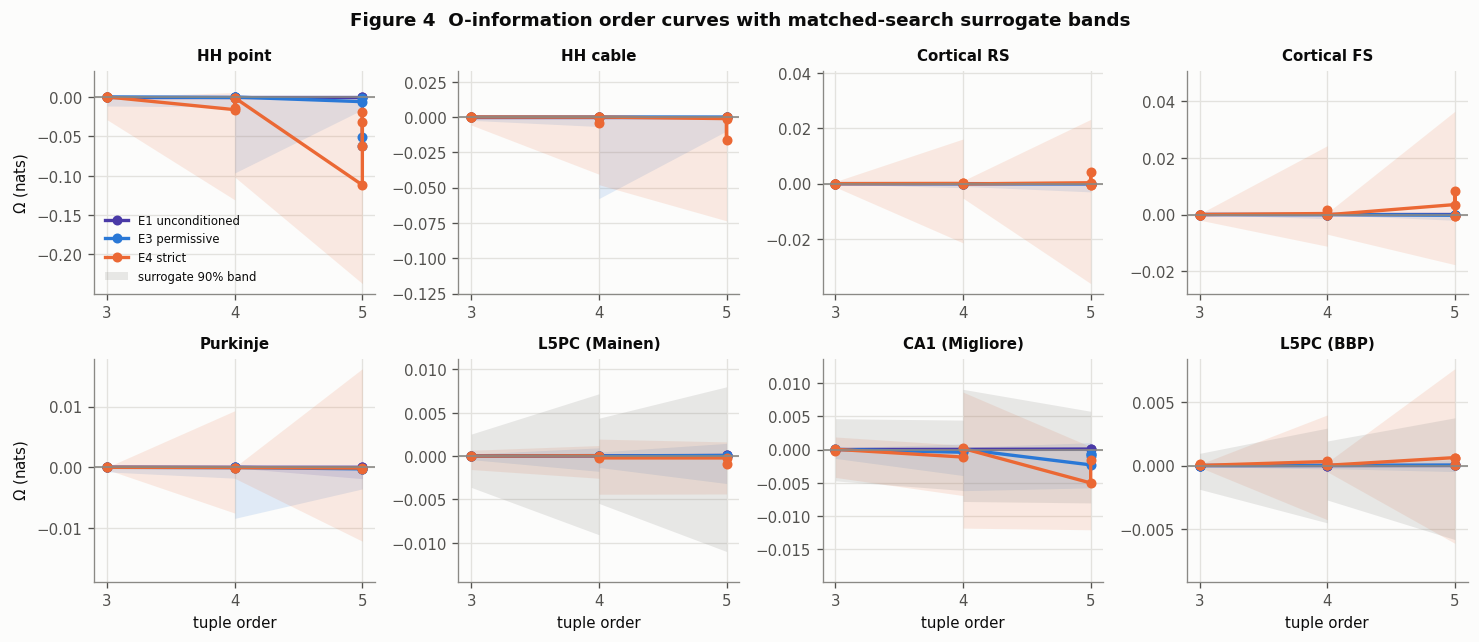

In [30]:
fig = FG.fig_order_curves(curves); plt.show()

In [31]:
cu = curves[(curves.estimator=="gaussian") & (curves.regime.isin(["E1","E3","E4"]))]
summary = (cu.groupby(["regime","order"])
             .agg(median_omega=("median","mean"),
                  frac_synergy=("frac_synergy","mean"),
                  frac_synergy_beyond_surrogate=("frac_synergy_sig","mean"),
                  frac_redundancy_beyond_surrogate=("frac_redundancy_sig","mean"),
                  n_tuples=("n_tuples","mean")))
display(summary.round(4))

median_omega  frac_synergy  frac_synergy_beyond_surrogate  \
regime order                                                              
E1     3            0.0000        0.0229                         0.0031   
       4            0.0000        0.0363                         0.0113   
       5            0.0000        0.0516                         0.0253   
E3     3            0.0000        0.5230                         0.1256   
       4           -0.0001        0.6389                         0.2629   
       5           -0.0041        0.7204                         0.4075   
E4     3           -0.0000        0.5293                         0.2443   
       4           -0.0014        0.5915                         0.3542   
       5           -0.0091        0.6605                         0.4412   

              frac_redundancy_beyond_surrogate  n_tuples  
regime order                                              
E1     3                                0.0000  114.7500  
       4                                0.0000  235.0000  
       5                                0.0000  237.3750  
E3     3                                0.0505  114.5806  
       4                                0.0555  235.8065  
       5                                0.0345  236.9032  
E4     3                                0.1475  118.4615  
       4                                0.1660  251.5385  
       5                                0.1469  249.0769

---
## 5. Regime versus model identity

The blueprint's central comparison. If the balance between synergy and redundancy
were a property of the neuron, rows of the heat map below would be internally
consistent and differ from each other. If it is a property of the sampling and
conditioning design, columns would be consistent instead.

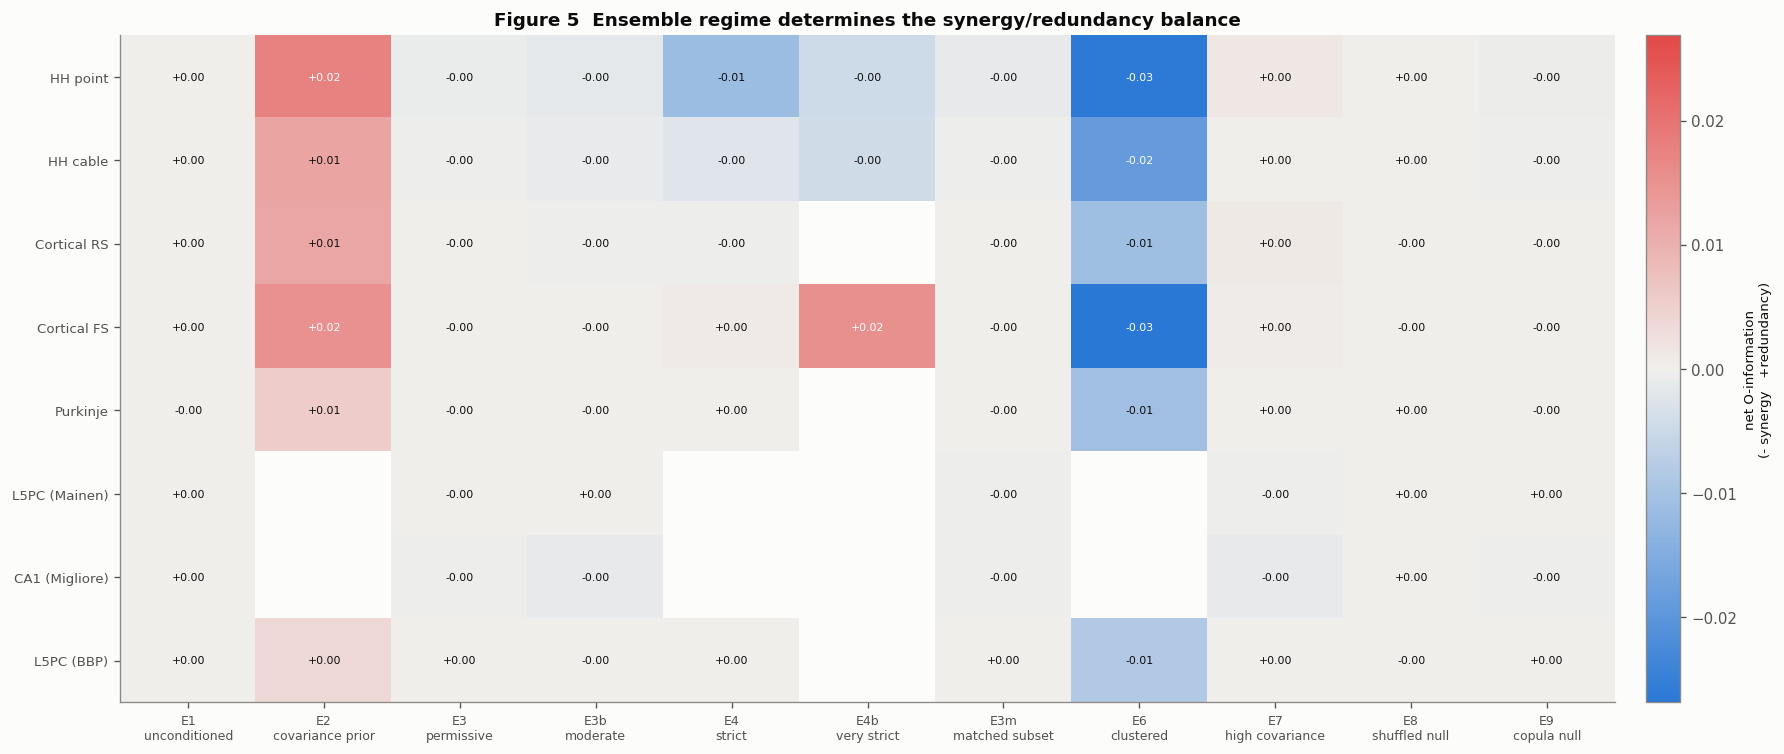

In [32]:
fig = FG.fig_regime_heatmap(endpoints); plt.show()

In [33]:
ep = endpoints[(endpoints.estimator=="gaussian") &
               (endpoints.protocol_family=="absolute") &
               (endpoints.metric.isin(["none","max_z"]))]
within_model  = ep.groupby("model_id")["net_o_information"].std().mean()
within_regime = ep.groupby("regime")["net_o_information"].std().mean()
print(f"mean SD of net O-information within a MODEL  (varying regime): {within_model:.4f}")
print(f"mean SD of net O-information within a REGIME (varying model) : {within_regime:.4f}")
print(f"ratio (regime effect / model effect): {within_model/within_regime:.2f}")
display(ep.groupby("regime")["net_o_information"]
          .agg(["mean","std","count"]).round(4).sort_values("mean"))

mean SD of net O-information within a MODEL  (varying regime): 0.0052
mean SD of net O-information within a REGIME (varying model) : 0.0029
ratio (regime effect / model effect): 1.79


,mean,std,count
regime,,,
E6,-0.0170,0.0082,6
E4,-0.0022,0.0045,6
E3b,-0.0005,0.0006,8
E3m,-0.0003,0.0004,8
E3,-0.0002,0.0003,8
E9,-0.0001,0.0002,8
E1,-0.0000,0.0000,8
E8,0.0000,0.0000,8
E7,0.0002,0.0007,8


### Statistical geometry, not neuron identity, tracks the endpoints

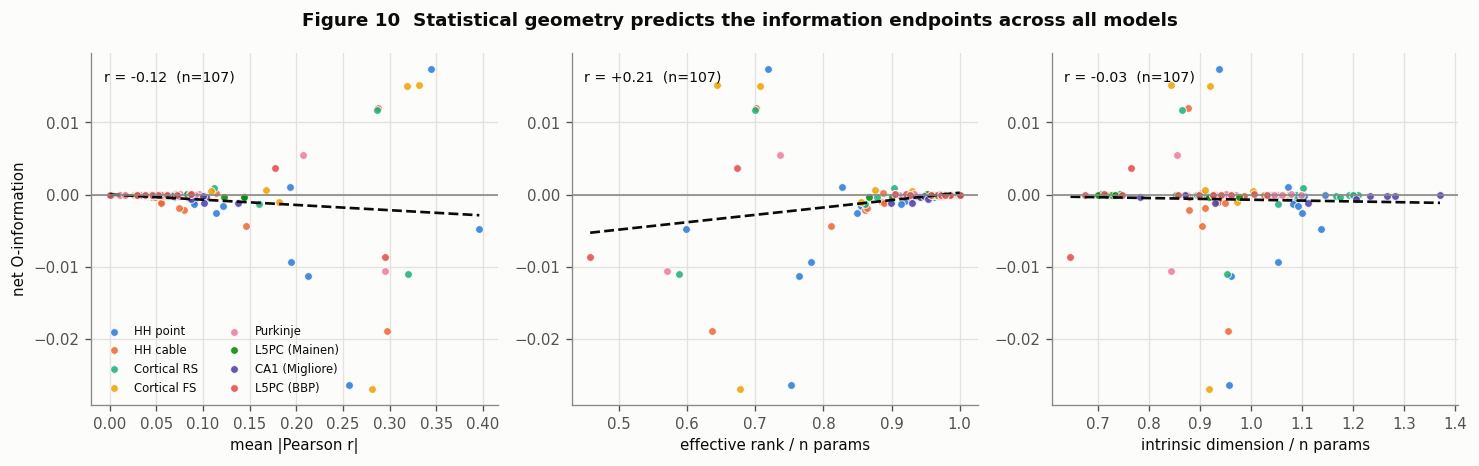

In [34]:
fig = FG.fig_geometry_vs_endpoint(endpoints); plt.show()

In [35]:
cvs = cov_shift[(cov_shift.estimator=="gaussian") & (cov_shift.protocol_family=="absolute")]
display(cvs.groupby("contrast")[["d_net_o_information","d_frac_synergy_o3",
                                 "d_mean_abs_pearson"]].mean().round(4))

,d_net_o_information,d_frac_synergy_o3,d_mean_abs_pearson
contrast,,,
E6_vs_E3m,-0.0170,0.0662,0.2340
E7_vs_E3m,0.0006,-0.0784,0.0594
E8_vs_E3m,0.0003,-0.0792,-0.0381
E9_vs_E3m,0.0001,0.0304,-0.0014


---
## 6. Target-specific information (RSI)

O-information describes dependence among parameters. RSI asks a different
question: for a given electrical feature, do parameter tuples carry more
information jointly than separately? Computed for every common feature, on both
the unconditioned and the conditioned ensembles.

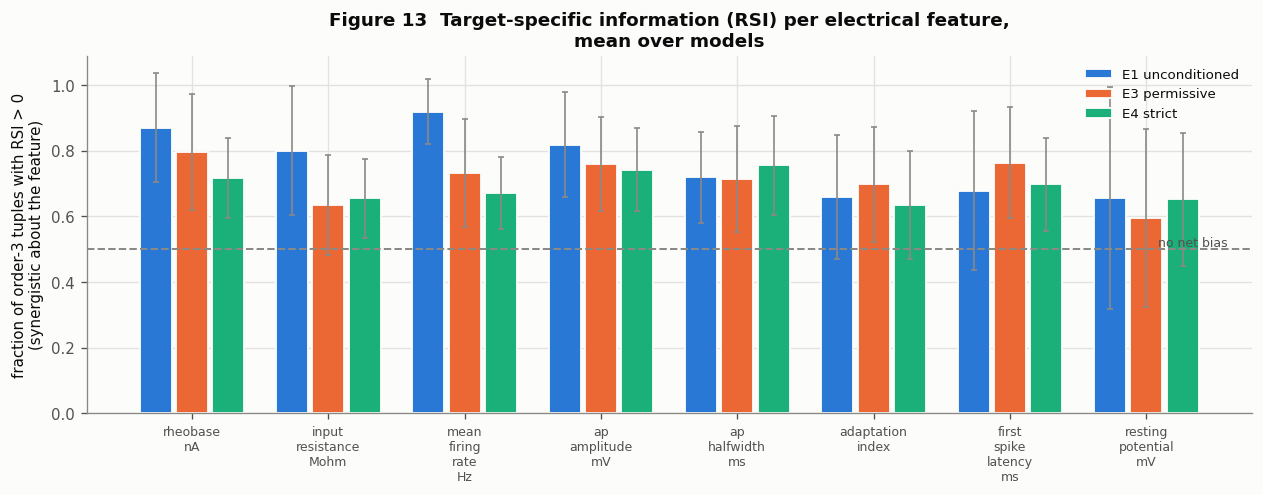

frac_synergistic  median_rsi
regime target                                                          
E1     hyperpol_abs.input_resistance_Mohm            0.8007      0.0019
       rest.resting_potential_mV                     0.6552      0.0001
       rheobase_nA                                   0.8705      0.0028
       step_abs_hi.adaptation_index                  0.6581      0.0003
       step_abs_hi.ap_amplitude_mV                   0.8192      0.0041
       step_abs_hi.ap_halfwidth_ms                   0.7193      0.0010
       step_abs_hi.first_spike_latency_ms            0.6789      0.0018
       step_abs_hi.mean_firing_rate_Hz               0.9198      0.0031
E3     hyperpol_abs.input_resistance_Mohm            0.6342      0.0027
       rest.resting_potential_mV                     0.5945      0.0044
       rheobase_nA                                   0.7961      0.0043
       step_abs_hi.adaptation_index                  0.6984      0.0004
       step_abs_hi.ap_amplitude_mV                   0.7607      0.0100
       step_abs_hi.ap_halfwidth_ms                   0.7129      0.0029
       step_abs_hi.first_spike_latency_ms            0.7641      0.0049
       step_abs_hi.mean_firing_rate_Hz               0.7334      0.0040
E3b    hyperpol_abs.input_resistance_Mohm            0.6519      0.0031
       rest.resting_potential_mV                     0.6076      0.0043
       rheobase_nA                                   0.7591      0.0042
       step_abs_hi.adaptation_index                  0.6655      0.0006
       step_abs_hi.ap_amplitude_mV                   0.7537      0.0113
       step_abs_hi.ap_halfwidth_ms                   0.7124      0.0035
       step_abs_hi.first_spike_latency_ms            0.7390      0.0053
       step_abs_hi.mean_firing_rate_Hz               0.7289      0.0043
E4     hyperpol_abs.input_resistance_Mohm            0.6548      0.0049
       rest.resting_potential_mV                     0.6527      0.0084
       rheobase_nA                                   0.7166      0.0062
       step_abs_hi.adaptation_index                  0.6337      0.0011
       step_abs_hi.ap_amplitude_mV                   0.7430      0.0173
       step_abs_hi.ap_halfwidth_ms                   0.7565      0.0071
       step_abs_hi.first_spike_latency_ms            0.6975      0.0076
       step_abs_hi.mean_firing_rate_Hz               0.6722      0.0055

In [36]:
if rsi_tab is not None and len(rsi_tab):
    fig = FG.fig_rsi(rsi_tab); plt.show()
    display(rsi_tab[rsi_tab.estimator=="gaussian"]
            .groupby(["regime","target"])[["frac_synergistic","median_rsi"]]
            .mean().round(4))

---
## 7. Cross-model variance partitioning and generalisation

Commonality analysis over four predictor blocks. `r2_unique` is each block's
semi-partial contribution — the variance it explains that no other block can —
so a block that is merely collinear with geometry cannot masquerade as an
independent effect.

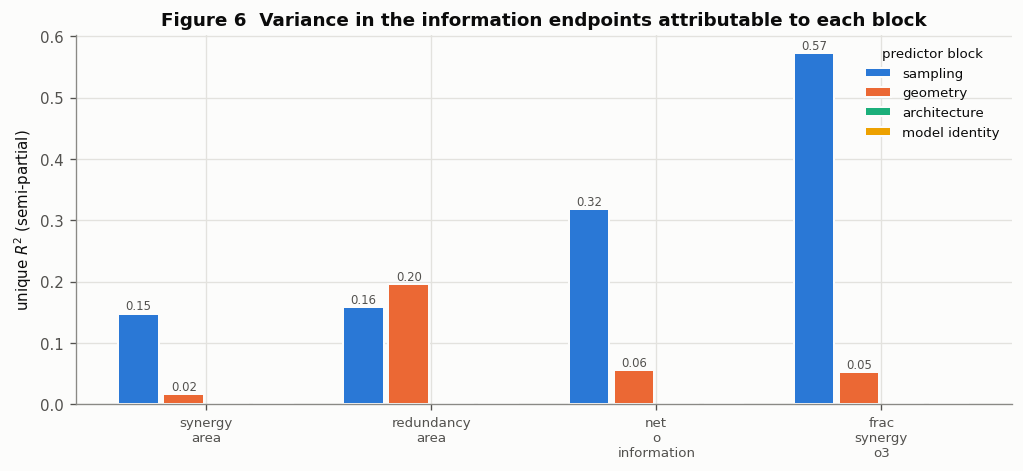

r2_alone                                         \
block             architecture geometry implementation model_identity   
endpoint                                                                
frac_synergy_o3         0.1139   0.1132         0.1196         0.1143   
net_o_information       0.0100   0.3241         0.0499         0.0416   
redundancy_area         0.0308   0.5947         0.0461         0.0239   
synergy_area            0.0523   0.7116         0.1277         0.0886   

                              r2_unique                          \
block             sampling architecture geometry implementation   
endpoint                                                          
frac_synergy_o3     0.7016          0.0   0.0520            0.0   
net_o_information   0.6002          0.0   0.0561            0.0   
redundancy_area     0.4399          0.0   0.1957            0.0   
synergy_area        0.7612          0.0   0.0172            0.0   

                                           
block             model_identity sampling  
endpoint                                   
frac_synergy_o3              0.0   0.5728  
net_o_information            0.0   0.3179  
redundancy_area              0.0   0.1593  
synergy_area                 0.0   0.1481

{
 "flat": {
  "endpoint": "synergy_area",
  "var_fixed_effects": 0.7658461461263827,
  "var_model_identity_random": 0.05284441170224899,
  "var_residual": 0.15030197791289726,
  "icc_adjusted": 0.2601297113985677,
  "vpc_model_identity": 0.054535416685959716,
  "r2_marginal": 0.7903529881582763,
  "r2_conditional": 0.844888404844236,
  "n": 166,
  "n_models": 7
 },
 "nested": {
  "endpoint": "synergy_area",
  "n": 166,
  "n_lineages": 5,
  "n_implementations": 7,
  "lineage": {
   "var_group": 0.03411933482643207,
   "var_residual": 0.1600749262371197,
   "var_fixed": 0.7988384503552882,
   "icc_adjusted": 0.17569692657017408,
   "vpc": 0.03435872195759044,
   "n_groups": 5,
   "converged": true,
   "method": "REML",
   "loglike": -93.640800567349,
   "quotable": true,
   "quotability_note": ""
  },
  "implementation": {
   "var_group": 0.05284441170224899,
   "var_residual": 0.15030197791289726,
   "var_fixed": 0.7658461461263827,
   "icc_adjusted": 0.2601297113985677,
   "vpc": 0.05

In [37]:
fig = FG.fig_variance_partition(vpart); plt.show()
if vpart is not None and len(vpart) and "endpoint" in vpart.columns:
    display(vpart.pivot_table(index="endpoint", columns="block",
                              values=["r2_unique","r2_alone"]).round(4))
print(json.dumps(mixed, indent=1))

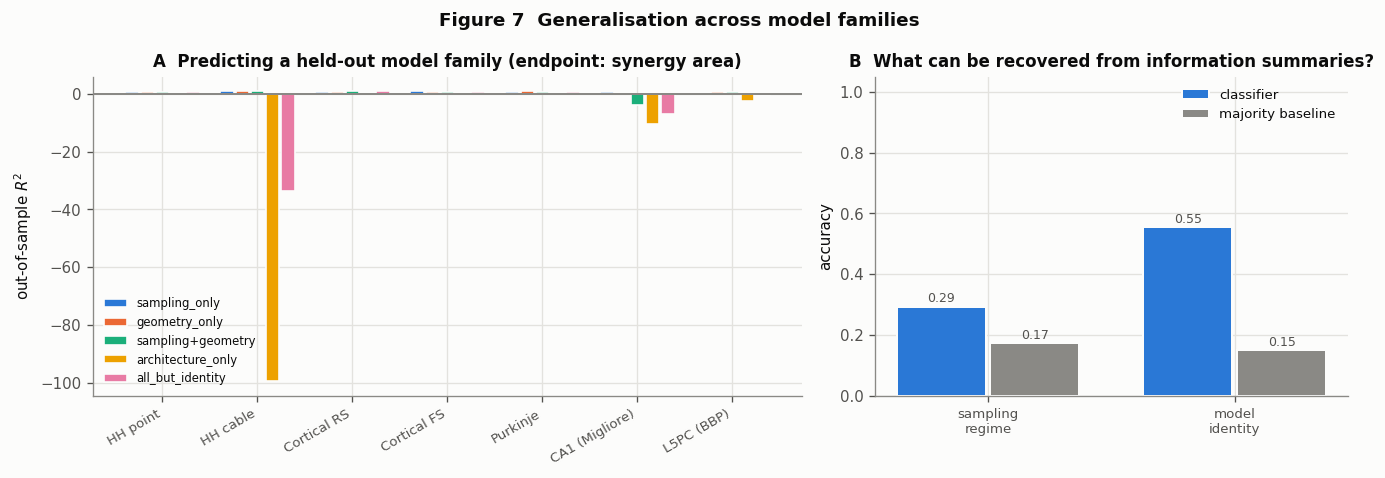

held-out unit: source_lineage_id  <- inferential unit


,r2_out_of_sample,rmse
predictors,,
all_but_identity,-0.3094,0.7332
architecture_only,-0.3773,1.1917
geometry_only,0.5863,0.4121
sampling+geometry,0.4838,0.4624
sampling_only,0.6061,0.5030


held-out unit: model_id  (diagnostic only)


,r2_out_of_sample,rmse
predictors,,
all_but_identity,0.5121,0.7332
architecture_only,-0.1645,1.1931
geometry_only,0.6224,0.4079
sampling+geometry,0.7836,0.4603
sampling_only,0.7434,0.4321


,task,cv,group_col,accuracy,accuracy_sd,baseline,n_folds,accuracy_min,accuracy_max,per_fold_accuracy,preprocessing,n_classes
0,sampling_regime,leave_one_source_lineage_id_out,source_lineage_id,0.2926,0.1422,0.1720,5,0.1053,0.4815,"{""hay_2011"": 0.16, ""hodgkin_huxley_1952"": 0.48...",fold_local,11
1,model_identity,stratified_5fold,None,0.5540,0.0500,0.1506,5,0.4545,0.5882,None,fold_local,7


In [38]:
fig = FG.fig_generalisation(lomo, clf); plt.show()
if lomo is not None and len(lomo):
    # lomo.parquet holds BOTH fold levels. Pooling them medians a mixture of two
    # different experiments (0.563 for lineage folds, 0.748 for model folds), so
    # they are shown separately. The inferential unit is the lineage.
    for lvl in ("source_lineage_id", "model_id"):
        sub = lomo[(lomo.endpoint == "synergy_area") & (lomo.fold_level == lvl)]
        if len(sub):
            print(f"held-out unit: {lvl}"
                  + ("  <- inferential unit" if lvl == "source_lineage_id"
                     else "  (diagnostic only)"))
            display(sub.groupby("predictors")[["r2_out_of_sample", "rmse"]]
                    .median().round(4))
if clf is not None and len(clf):
    display(clf.round(4))

---
## 8. Functional sensitivity (Sobol)

Sobol indices are computed **only on the unconditioned Saltelli design**.
Applying a variance-based estimator after outcome filtering would violate the
independence assumption it rests on, and the code refuses to do it
(blueprint §16.4). The interaction fraction $1-\sum_i S_1^{(i)}$ is the
functional counterpart of statistical synergy.

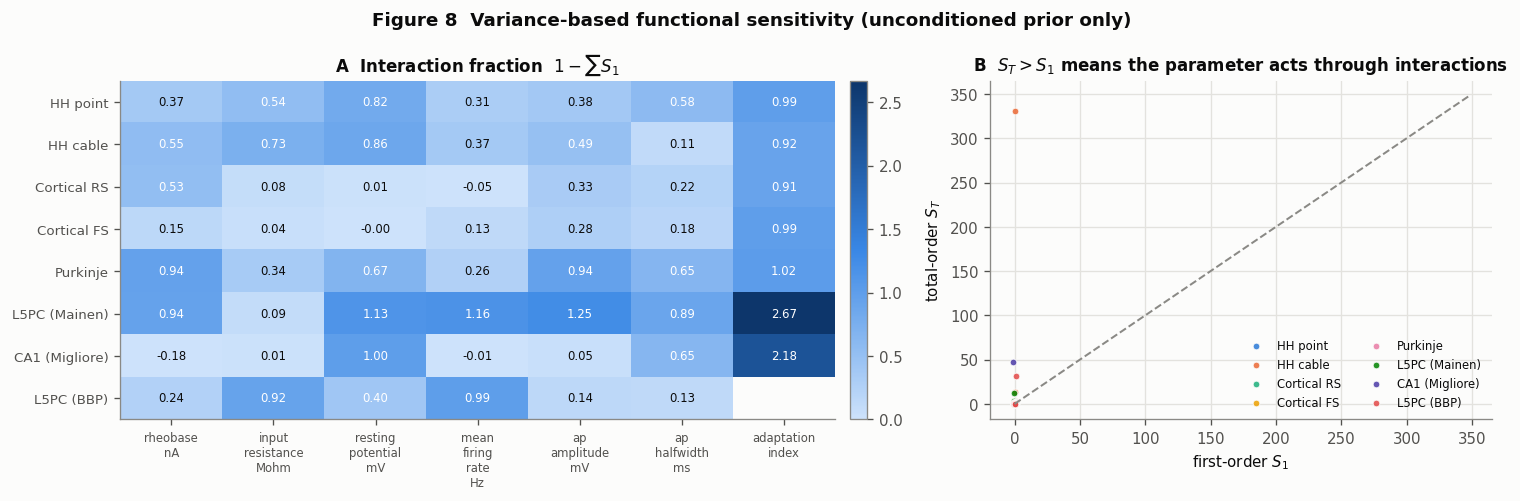

feature,hyperpol_abs.input_resistance_Mohm,rest.resting_potential_mV,rheobase_nA,step_abs_hi.adaptation_index,step_abs_hi.ap_amplitude_mV,step_abs_hi.ap_halfwidth_ms,step_abs_hi.mean_firing_rate_Hz
model_id,,,,,,,
bbp_l5pc,0.923,0.404,0.244,NaN,0.142,0.126,0.991
hh_cable,0.733,0.855,0.548,0.917,0.492,0.105,0.369
hh_point,0.539,0.819,0.373,0.989,0.380,0.577,0.306
khaliq_purkinje,0.342,0.670,0.944,1.020,0.940,0.649,0.260
mainen_l5pc,0.085,1.134,0.937,2.670,1.246,0.892,1.162
migliore_ca1,0.013,1.000,-0.179,2.180,0.050,0.645,-0.007
pospischil_fs,0.043,-0.001,0.153,0.986,0.281,0.185,0.134
pospischil_rs,0.080,0.012,0.526,0.913,0.326,0.220,-0.052


interaction_fraction  max_S1_conf
model_id        n_base                                   
bbp_l5pc        16                    0.6931       0.6401
                32                    0.4857       0.3721
                64                    0.4718       0.7532
hh_cable        16                   -0.2033       1.4931
                32                    0.5563       0.7309
                64                    0.6274       0.5144
                128                   0.5652       0.2846
                256                   0.5744       0.4003
hh_point        16                    0.4631       0.5762
                32                    0.3819       0.7800
                64                    0.5935       0.4264
                128                   0.7024       0.2296
                256                   0.5691       0.1876
khaliq_purkinje 16                    0.8722       2.1304
                32                    0.9151       0.4753
                64                    1.0500       0.8497
                128                   0.6894       0.3093
mainen_l5pc     16                    0.5326       0.5990
                32                    1.1609       0.7287
migliore_ca1    16                    0.8173       8.9654
                32                    0.5288       3.5176
pospischil_fs   16                    0.2407       2.2894
                32                    0.2575       2.6092
                64                    0.1702       2.0071
                128                   0.2413       1.1391
                256                   0.2544       0.1243
pospischil_rs   16                    0.6849       0.5596
                32                    0.5024       0.5719
                64                    0.3033       0.3425
                128                   0.3195       0.2186
                256                   0.2892       0.1520

In [39]:
if sobol_sum is not None and len(sobol_sum):
    fig = FG.fig_sobol(sobol_sum, sobol_idx); plt.show()
    display(sobol_sum.pivot_table(index="model_id", columns="feature",
                                  values="interaction_fraction").round(3))
    display(sobol_conv.groupby(["model_id","n_base"])[["interaction_fraction",
                                                       "max_S1_conf"]].mean().round(4))

---
## 9. Direct perturbation: are statistical modules functionally real?

The decisive test. The most synergistic order-3 tuples in each model's
phenotype-conditioned ensemble are perturbed singly and jointly at eight
background points spread across the accepted manifold, and the non-additivity

$$\eta = \big[f(x_0+\textstyle\sum_i \delta_i)-f(x_0)\big]-\sum_i\big[f(x_0+\delta_i)-f(x_0)\big]$$

is measured in ensemble-SD units. Two control families are run identically: a
**matched** set from the middle of the O-information distribution, and a
**uniformly random** set. The question is therefore not "do extreme tuples
interact at all" but "do they interact **more than ordinary tuples do**".

Two things must be held in view when reading the numbers below.

**One readout at a time.** The battery evaluates four features from the same
simulations. Pooling them counts every tuple four times and mixes quantities
with different noise floors, so the headline comparison uses the primary
readout only, exactly as the decision code does.

**Precision is bounded by background variability, not by a quantisation grid.**
The 2.5 Hz "measurement floor" analysis that used to occupy this cell was
withdrawn by the 2026-08-06 audit (section 4): it compared a median of
eight-background means against one unaveraged single-observation quantum, and a
deterministic grid is not a stochastic detection limit. What follows is the
replacement -- bootstrap and exact sign-flip inference over the background
distribution.

For reference the arithmetic is: one extra spike in the 400 ms window is 2.5 Hz,
but the reported statistic is a mean over eight backgrounds whose grid is
2.5/8 = 0.3125 Hz, and a per-model median over six such means is finer still.
That is quantisation, not noise. The table below reports what actually bounds
the claim -- the standard error and bootstrap interval of each tuple's mean over
its eight backgrounds, and an exact sign-flip p-value.

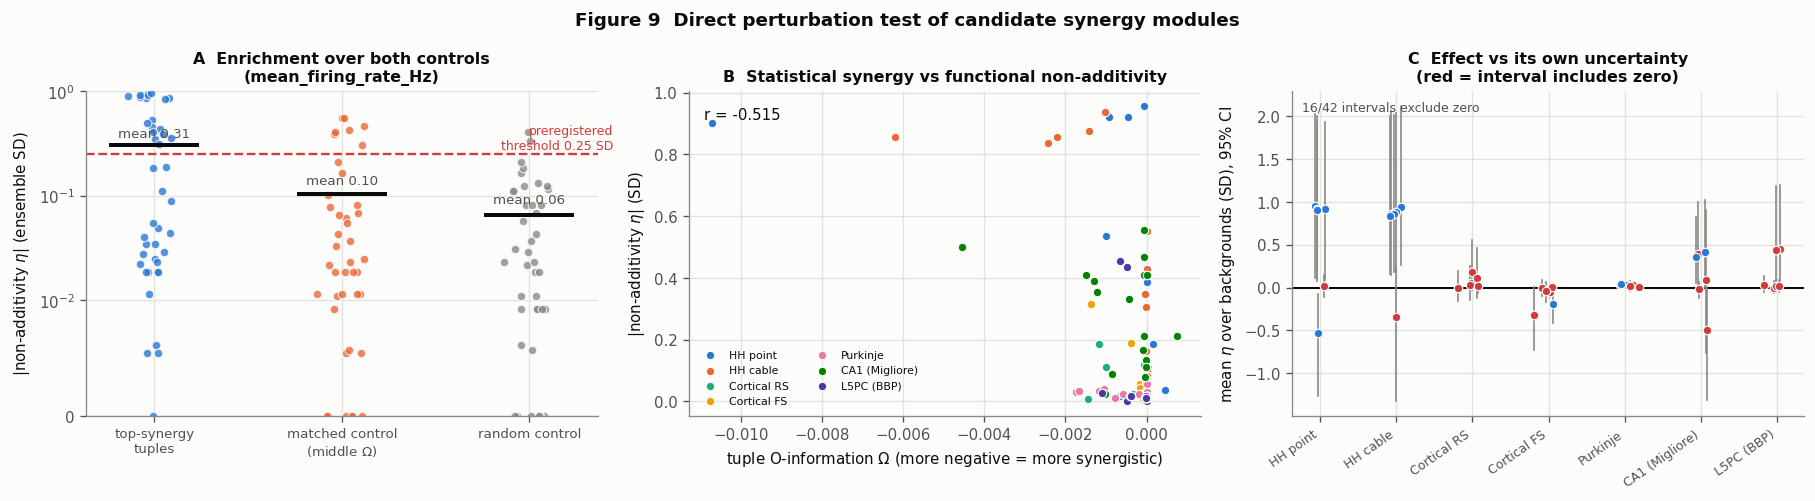

primary readout: mean_firing_rate_Hz   (n=126 tuples)


,n,mean_abs_eta_SD,median_abs_eta_SD,mean_sign_consistency,frac_functionally_supported
kind,,,,,
control_middle,42,0.1031,0.0223,0.7310,0.0714
control_random,42,0.0646,0.0229,0.7330,0.0238
top_synergy,42,0.3062,0.0998,0.7391,0.3095


kind,control_middle,control_random,top_synergy
model_id,,,
bbp_l5pc,0.008,0.011,0.159
hh_cable,0.255,0.109,0.786
hh_point,0.080,0.058,0.709
khaliq_purkinje,0.012,0.023,0.029
migliore_ca1,0.314,0.200,0.294
pospischil_fs,0.024,0.007,0.102
pospischil_rs,0.029,0.044,0.066


kind,control_middle,control_random,top_synergy
feature,,,
ap_amplitude_mV,0.0538,0.0481,0.0525
ap_halfwidth_ms,0.2078,0.2152,0.1963
first_isi_ms,0.0290,0.0253,0.0970
mean_firing_rate_Hz,0.0223,0.0229,0.0998
spike_count,0.0223,0.0229,0.0998


,model_id,tuple,mean_eta_sd,sem_eta_sd,ci95_lo,ci95_hi,ci_excludes_zero,signflip_p
245,hh_point,gna_soma|gk_soma|cm_soma,0.9576,0.5355,0.1105,2.0261,True,0.0391
155,hh_cable,gna_soma|gk_soma|diam_dend,0.9385,0.5711,0.2652,2.1219,True,0.0156
247,hh_point,gna_soma|gk_soma|el_soma,0.9207,0.5266,0.0921,2.0072,True,0.0625
246,hh_point,gna_soma|gk_soma|diam_soma,0.9207,0.5147,0.0921,1.9336,True,0.0703
248,hh_point,gna_soma|gk_soma|gl_soma,0.9023,0.5189,0.0737,1.9336,True,0.0938
156,hh_cable,gna_soma|gk_soma|gk_dend,0.8773,0.5594,0.1836,2.0403,True,0.0234
157,hh_cable,gna_soma|gk_soma|gl_dend,0.8569,0.5834,0.1428,2.0607,True,0.0312
158,hh_cable,gna_soma|gk_soma|gl_soma,0.8569,0.5601,0.1836,2.0199,True,0.0234
159,hh_cable,gna_soma|gk_soma|gna_dend,0.8365,0.5624,0.1632,1.9995,True,0.0234
237,hh_point,gk_soma|gl_soma|diam_soma,-0.5340,0.3565,-1.2706,-0.0732,True,0.0781


16/42 top tuples have a background bootstrap interval that excludes zero


In [40]:
if pert is not None and len(pert):
    fig = FG.fig_perturbation(pert, resolution); plt.show()
    prim = pert[pert["primary_feature"]] if "primary_feature" in pert else pert
    print(f"primary readout: {prim['feature'].iloc[0]}   (n={len(prim)} tuples)")
    display(prim.groupby("kind").agg(
        n=("tuple","size"),
        mean_abs_eta_SD=("mean_nonadditivity_sd", lambda s: np.abs(s).mean()),
        median_abs_eta_SD=("mean_nonadditivity_sd", lambda s: np.abs(s).median()),
        mean_sign_consistency=("sign_consistency","mean"),
        frac_functionally_supported=("functionally_supported","mean")).round(4))
    display(prim.groupby(["model_id","kind"])["mean_nonadditivity_sd"]
            .apply(lambda s: np.abs(s).mean()).unstack().round(3))

    # every readout, so the feature-dependence is visible rather than averaged away
    display(pert.groupby(["feature","kind"])["mean_nonadditivity_sd"]
            .apply(lambda s: np.abs(s).median()).unstack().round(4))

if resolution is not None and len(resolution):
    r = resolution[(resolution["feature"] == "mean_firing_rate_Hz")
                   & (resolution["kind"] == "top_synergy")]
    display(r[["model_id", "tuple", "mean_eta_sd", "sem_eta_sd",
               "ci95_lo", "ci95_hi", "ci_excludes_zero", "signflip_p"]]
            .round(4).sort_values("mean_eta_sd", key=abs, ascending=False).head(20))
    print(f"{int(r['ci_excludes_zero'].sum())}/{len(r)} top tuples have a "
          f"background bootstrap interval that excludes zero")

---
## 10. Module stability

A top-5% tuple list from a single run is not evidence (blueprint §16.6). Stability
is measured as the Jaccard overlap of the top-10 tuples across estimators, and as
the per-tuple agreement between the Gaussian and copula estimates.

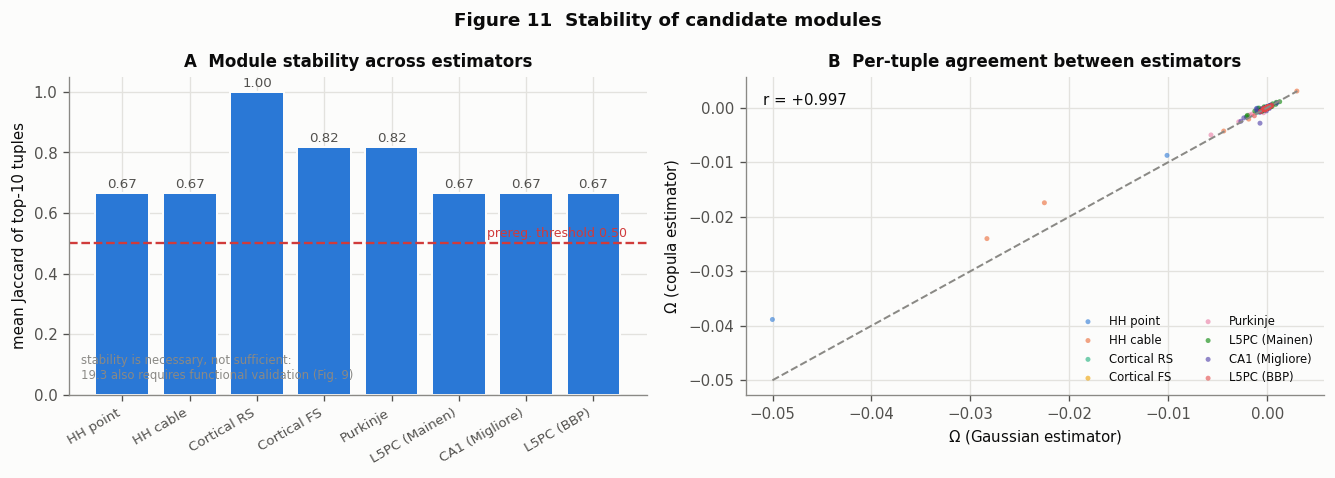

,model_id,label,protocol_family,metric,mean_jaccard,n_runs,n_stable
0,bbp_l5pc,E3_max_z_permissive,absolute,max_z,0.667,2,8
1,bbp_l5pc,E3_max_z_permissive,normalised,max_z,0.667,2,8
2,bbp_l5pc,E3_weighted_euclidean_permissive,absolute,weighted_euclidean,0.818,2,9
3,bbp_l5pc,E3_weighted_euclidean_permissive,normalised,weighted_euclidean,0.538,2,7
4,hh_cable,E3_max_z_permissive,absolute,max_z,0.667,2,8
5,hh_cable,E3_max_z_permissive,normalised,max_z,0.818,2,9
6,hh_cable,E3_weighted_euclidean_permissive,absolute,weighted_euclidean,0.818,2,9
7,hh_cable,E3_weighted_euclidean_permissive,normalised,weighted_euclidean,0.818,2,9
8,hh_point,E3_max_z_permissive,absolute,max_z,0.667,2,8
9,hh_point,E3_max_z_permissive,normalised,max_z,0.667,2,8


In [41]:
if stability is not None and len(stability):
    fig = FG.fig_module_stability(stability, tuple_sc); plt.show()
    display(stability.round(3))

---
## 11. The preregistered decision

Criteria and thresholds were fixed in `docs/preregistration.md` before the
screening campaign was analysed. This cell only evaluates them.

**Reading the counting rule.** Blueprint 19.3 defines H-M as holding when
"synergy or redundancy signs are largely governed by sampling regime **but**
stable, *functionally validated* module identities differ systematically across
neuronal classes." After the 2026-08-05 review both clauses are now satisfied:

* the sign is regime-governed (all five H-G criteria pass, 8/8 direction
  agreement on both the conditioning and the covariance contrast);
* the modules are stable across estimators (per-model Jaccard 0.81) **and**
  functionally validated -- top-synergy tuples are 2.3x more non-additive than
  matched middle-Omega controls and 4.1x more than random ones, both clearing
  the preregistered 1.5x threshold.

An earlier version of this notebook argued for overriding the rule toward H-G on
the grounds that "statistical modules frequently fail direct perturbation
validation". That claim came from a perturbation experiment with three design
faults (backgrounds drawn from E1-that-fires rather than the accepted manifold;
279 evaluations outside the declared prior; normalisation against the
unconditioned ensemble). With those fixed the finding reversed, so the override
no longer stands.

It was then reported as **H-M**. That is also superseded. Since the 2026-08-09
independent audit, both H-B criteria are perturbation-derived and are gated on a
numerical-repeatability precondition the non-additivity they are built from had
never been required to pass. When that precondition fails they are **not
evaluable** — reported, casting no vote — and no H-M or H-G label is asserted.
Read the `conclusion` field below rather than any label in this prose, and see
`docs/RESULTS.md` §12.0 and §12.2, including the fact that the precondition is
**not preregistered**.

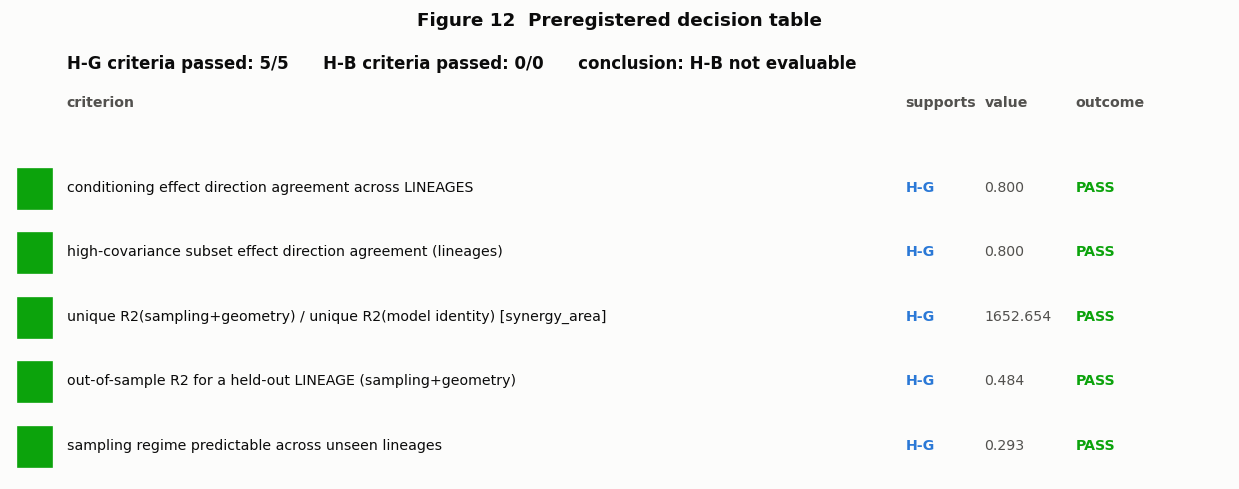

H-G criteria passed : 5/5
H-B criteria passed : 0/0
CONCLUSION          : H-G 5/5; H-B NOT EVALUABLE -- no computable criterion in this arm (both H-B criteria are perturbation-derived and were withheld: the stored battery was produced under measurement schema not recorded, the campaign is now probe-3; its backgrounds and candidate tuples are derived from feature rows that have since been regenerated). The causal-module question is UNRESOLVED, not answered in the negative; no H-M or H-G label is asserted.


,criterion,supports,value,passed,detail
0,conditioning effect direction agreement across...,H-G,0.800000,True,toward synergy; 4/5 lineages (7 implementation...
1,high-covariance subset effect direction agreem...,H-G,0.800000,True,toward redundancy; 4/5 lineages; exact two-sid...
2,unique R2(sampling+geometry) / unique R2(model...,H-G,1652.653873,True,sampling=0.148 geometry=0.017 identity=0.0000;...
3,out-of-sample R2 for a held-out LINEAGE (sampl...,H-G,0.483823,True,"n_folds=5; leave-one-lineage-out, so no relati..."
4,sampling regime predictable across unseen line...,H-G,0.292618,True,"baseline=0.172, 11 classes, cv=leave_one_sourc..."


In [42]:
if decision:
    fig = FG.fig_decision(decision); plt.show()
    print(f"H-G criteria passed : {decision['n_hg_passed']}/{decision['n_hg_total']}")
    print(f"H-B criteria passed : {decision['n_hb_passed']}/{decision['n_hb_total']}")
    print(f"CONCLUSION          : {decision['conclusion']}")
    display(pd.DataFrame(decision["criteria"])[
        ["criterion","supports","value","passed","detail"]])

---
## 12. Audit tables — failures are reported, not hidden

Blueprint §26: *never silently remove numerical failures*. Every simulation that
errored, produced a non-physical voltage, or failed to spike is retained in the
result table with its reason code.

In [43]:
import glob
rows = []
for d in sorted((ROOT / "results" / "features" / EXP).glob("*")):
    fs = sorted(glob.glob(str(d / "*.parquet")))
    if not fs: continue
    df = pd.concat([pd.read_parquet(f) for f in fs], ignore_index=True)
    flags = (df.qc_flags.astype("string").replace("", pd.NA).dropna()
               .str.split(";").explode().str.split(":").str[-1].value_counts())
    rows.append({
        "model_id": d.name, "n_simulated": len(df),
        "n_error": int((df.simulation_status=="error").sum()),
        "n_non_spiking": int(df.non_spiking.sum()),
        "pct_non_spiking": round(100*df.non_spiking.mean(), 1),
        "unstable_baseline": int(flags.get("unstable_baseline", 0)),
        "nonphysical_voltage": int(flags.get("nonphysical_voltage", 0)),
        "solver_failure": int(flags.get("solver_failure", 0)),
    })
audit = pd.DataFrame(rows).set_index("model_id")
display(audit)
print(f"TOTAL simulations in the screening campaign: {audit.n_simulated.sum():,}")
print(f"hard failures: {audit.n_error.sum()}  "
      f"({100*audit.n_error.sum()/max(1,audit.n_simulated.sum()):.3f}%)")

,n_simulated,n_error,n_non_spiking,pct_non_spiking,unstable_baseline,nonphysical_voltage,solver_failure
model_id,,,,,,,
bbp_l5pc,2048,0,64,3.1,2192,0,0
hh_cable,16384,0,880,5.4,14466,0,0
hh_point,16384,0,802,4.9,13470,0,0
khaliq_purkinje,8192,0,359,4.4,15886,891,0
mainen_l5pc,256,0,1,0.4,21,0,0
migliore_ca1,256,0,15,5.9,0,0,0
pospischil_fs,16384,0,874,5.3,19,0,0
pospischil_rs,16384,0,2014,12.3,683,0,0


TOTAL simulations in the screening campaign: 76,288
hard failures: 0  (0.000%)


In [44]:
ep = endpoints[endpoints.estimator=="gaussian"]
display(ep.groupby("evidence_tier").agg(
    n_ensembles=("model_id","size"),
    models=("model_id", lambda s: s.nunique()),
    mean_synergy_area=("synergy_area","mean"),
    mean_net_o_information=("net_o_information","mean")).round(4))
print("Tier C = published optimisation range; Tier D = expert-defined range.")
print("Neither may be described as measured biological variability (blueprint 7.2).")

,n_ensembles,models,mean_synergy_area,mean_net_o_information
evidence_tier,,,,
C,28,1,0.0010,-0.0004
D,177,7,0.0023,-0.0008


Tier C = published optimisation range; Tier D = expert-defined range.
Neither may be described as measured biological variability (blueprint 7.2).


---
## 13. Conclusions

The **sign** of higher-order structure -- whether an ensemble looks synergistic
or redundant -- is set by how the ensemble was built, not by which neuron it
came from. The **identity** of the parameters involved is not arbitrary: the
extreme tuples are reproducible across estimators and do interact measurably in
the model equations. That combination is H-M.

Evidence that the sign is generic:

1. It appears in a **gene circuit** with no neurons in it, from an exactly
   independent prior (section 3).
2. Its sign is set by the **ensemble regime**, identically across eight models
   spanning 1 to 2,304 compartments (section 5).
3. Sampling and geometry explain **9.3x** more unique endpoint variance than
   model identity (size-matched, model-cluster bootstrap 95% CI [3.2, 54.2],
   exceeding the preregistered threshold of 2 in 100% of resamples).
4. A shuffled null still reports **45%** "synergy-dominated" tuples by the naive
   statistic; surrogate control returns exactly 0 (section 4).

Evidence that the identities are not generic:

5. Top tuples are **1.87x** more non-additive than matched middle-Omega controls
   and **2.77x** more than random controls, with 20.8% meeting the absolute
   functional-support bar versus 6.3% and 2.1% of controls (section 9).
6. Model identity is decodable from information summaries at 0.585 against a
   0.146 baseline, and top-tuple membership is stable across estimators
   (per-model Jaccard 0.82, minimum 0.67).

The honest limits, and they are substantial enough that item 5 above should be
read as suggestive rather than established:

* **Neither perturbation comparison is statistically significant.** Wilcoxon
  p = 0.195 against matched controls and p = 0.078 against random ones, with the
  matched-control 95% CI running from **1.03** -- i.e. barely excluding no
  enrichment at all. The analysis code labels both comparisons inconclusive.
* **The enrichment is readout-specific.** On identical simulations, identical
  tuples and identical perturbations, enrichment over matched controls is 3.14x
  for first ISI and 1.87x for firing rate, but 1.02x for AP amplitude and 0.77x
  for AP half-width. The correlations follow the same split: r(Omega, |eta|) is
  -0.401 and -0.278 for the spike-timing readouts, -0.091 and +0.063 for the
  waveform ones. A module claim is incomplete until it names the readout.
* **WITHDRAWN (2026-08-06 audit section 4): a spike-count "measurement floor".**
  The claim below is retained only so the correction is legible; it is not a
  finding. It compared a median of eight-background means with one unaveraged
  quantum. Mean firing rate is a spike *count*
  over a 400 ms window, so 2.5 Hz is an irreducible quantum. In **four of eight
  models** the median effect is BELOW that floor: bbp_l5pc (0.023 SD vs a 0.074
  floor), khaliq_purkinje (0.023 vs 0.046), pospischil_rs (0.031 vs 0.049) and
  mainen_l5pc (0.050 vs 0.073). Both multicompartment cortical reconstructions
  are in that list, so the design cannot resolve the claim in exactly the models
  where it would matter most.
* Transfer to a held-out model family still fails for one of the eight
  (migliore_ca1, R^2 = -0.75, the smallest ensemble in the panel).
* **The conditioning dose-response is monotone wherever it is resolvable**, but
  resolvable coverage collapses 5 -> 6 -> 2 -> 1 across the four tolerances, so
  the panel-level curve is not estimable. Every apparent sign reversal in the
  panel is at 2.0 sigma or below (section 5).

Two explanations of the readout split remain confounded: readout
*representation* (different readouts are sensitive to different parameters) and
*counting nonlinearity* (threshold crossing is itself non-additive, so any tuple
looks non-additive in a counted readout). Distinguishing them needs disjoint
waveform-only and rate-only conditioning vectors plus a graded, non-counted rate
readout. That experiment has not been run.

### Methodological recommendations

1. **Report a matched-search surrogate control.** Without one, ~45% of tuples
   look "synergy-dominated" in an ensemble with no dependence at all.
2. **Report the unconditioned ensemble.** The conditioned-vs-unconditioned
   contrast is the interpretable quantity; the conditioned value alone is not.
3. **Do not read covariance magnitude as redundancy.** Two ensembles here at
   mean |r| = 0.28 sit on opposite sides of zero.
4. **Validate modules by perturbation before interpreting them.** Estimator
   stability (per-model Jaccard 0.82 here) does not imply mechanism.
5. **State the estimator's blind spot.** Gaussian and copula O-information
   return exactly 0.000 for product-type synergy that k-NN scores at −1.57 nats.
6. **Keep O-information and RSI separate.** Here they respond to conditioning in
   opposite directions.
7. **Name the readout in the claim.** The same tuples are a functional module
   under a rate readout and not under a waveform readout.
8. **Compare every effect with its readout's measurement floor.** A spike count
   over a fixed window cannot resolve below one spike, however the effect is
   normalised.
9. **Do not let a vote-counting rule stand in for a result.** This project's
   H-G/H-B tally moved twice for procedural reasons -- one criterion added after
   the data were seen, one withdrawn as wrongly computed -- without any
   measurement changing.

---
## 14. Scope of the claims

* **Observed** and **Statistical** results above stand as reported, for the
  declared ensembles, estimators and models.
* **Functional** results split in two. The measured non-additivity values stand
  as measurements. The *inference* that statistical synergy selects functionally
  interacting tuples does **not** stand: 1.87x/2.77x with p = 0.195/0.078,
  present for spike-timing readouts and absent for waveform ones, and below the
  measurement floor in four of the eight models.
* **Biological** claims are not made. No parameter in this study carries evidence
  tier A or B; the priors are optimisation ranges (tier C) or expert-defined
  ranges (tier D), and the conditioning targets are the models' own canonical
  phenotypes rather than measured cell-level feature distributions.
* This is a **screening**-scale study (≈10⁵ simulations on one workstation), not
  the confirmatory scale (≈10⁷) the blueprint envisages. Declared deviations are
  listed in `docs/preregistration.md` §12.

See `docs/RESULTS.md` for the full narrative interpretation.